In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn openpyxl

Note: you may need to restart the kernel to use updated packages.


# 04. Customer segmentation with RFM

## What RFM means, before we use it

RFM is three simple ideas about a customer.

- Recency: how many days since their last order. Smaller is better, because a recent buyer is easier to reach.
- Frequency: how many distinct orders they placed. More orders usually means a stronger habit.
- Monetary: how much money they spent in total. More spending means more value so far.

Each customer gets a score from 1 to 4 on each idea, using quartiles. A quartile splits customers into four equal sized groups. For recency, the most recent group gets 4. For frequency and monetary, the highest group gets 4. The three scores add up to a total from 3 to 12.

## Segment rules used here

- Champions: total 10 or more.
- Loyal: total 8 or 9.
- Potential loyal: recent (recency score 3 or more) and ordered at least at the second frequency level, but total below 8.
- Recent buyers: recent, but not yet frequent.
- At risk: recency score 2 and ordered at least at the second frequency level.
- Lost or hibernating: everyone else.

These rules are a teaching choice, not a law of business. A different shop could draw the lines differently, and the notebook shows the counts so the reader can judge the result.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
plt.rcParams['figure.dpi'] = 120
ROOT = Path('..').resolve()
CHARTS = ROOT / 'charts'
CHARTS.mkdir(exist_ok=True)
DATA = ROOT / 'data' / 'processed'
RAW = ROOT / 'data' / 'raw' / 'online_retail.csv'
print('Charts folder:', CHARTS)
print('Data folder:', DATA)


Charts folder: /home/hatch/workspace/repo-builds/datanalytics-project/charts
Data folder: /home/hatch/workspace/repo-builds/datanalytics-project/data/processed


In [3]:
rfm = pd.read_csv(DATA / 'rfm_segments.csv')
print(rfm.head(10).to_string(index=False))
print(rfm.describe().to_string())
print('Median recency, days:', rfm['recency'].median())
print('Median frequency, orders:', rfm['frequency'].median())
print('Median monetary, pounds:', round(rfm['monetary'].median(), 2))

 CustomerID  recency  frequency  monetary  R_score  F_score  M_score  RFM_total             segment
    12346.0      326          1  77183.60        1        1        4          6 Lost or hibernating
    12347.0        2          7   4310.00        4        3        4         11           Champions
    12348.0       75          4   1797.24        2        2        4          8               Loyal
    12349.0       19          1   1757.55        3        1        4          8               Loyal
    12350.0      310          1    334.40        1        1        2          4 Lost or hibernating
    12352.0       36          8   2506.04        3        3        4         10           Champions
    12353.0      204          1     89.00        1        1        1          3 Lost or hibernating
    12354.0      232          1   1079.40        1        1        3          5 Lost or hibernating
    12355.0      214          1    459.40        1        1        2          4 Lost or hibernating


            segment  customers     revenue   avg_spend  share_customers  share_revenue
          Champions        797 5767945.430 7237.070803        18.372522      64.725411
              Loyal        831 1595780.541 1920.313527        19.156293      17.907165
Lost or hibernating       1717 1023936.752  596.352214        39.580452      11.490179
      Recent buyers        659  258264.170  391.903141        15.191332       2.898130
            At risk        243  221936.121  913.317370         5.601660       2.490472
    Potential loyal         91   43544.890  478.515275         2.097741       0.488642


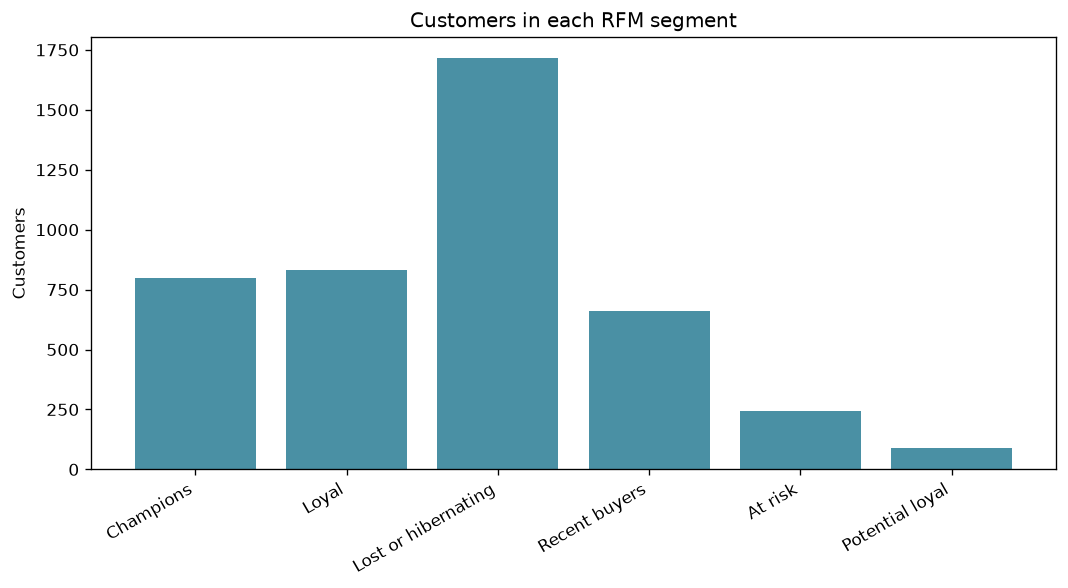

In [4]:
seg = rfm.groupby('segment').agg(customers=('CustomerID', 'count'), revenue=('monetary', 'sum'), avg_spend=('monetary', 'mean')).reset_index().sort_values('revenue', ascending=False)
seg['share_customers'] = seg['customers'] / seg['customers'].sum() * 100
seg['share_revenue'] = seg['revenue'] / seg['revenue'].sum() * 100
print(seg.to_string(index=False))
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(seg['segment'], seg['customers'], color='#4a90a4')
ax.set_title('Customers in each RFM segment')
ax.set_ylabel('Customers')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(CHARTS / '10_segment_customers.png')
plt.show()

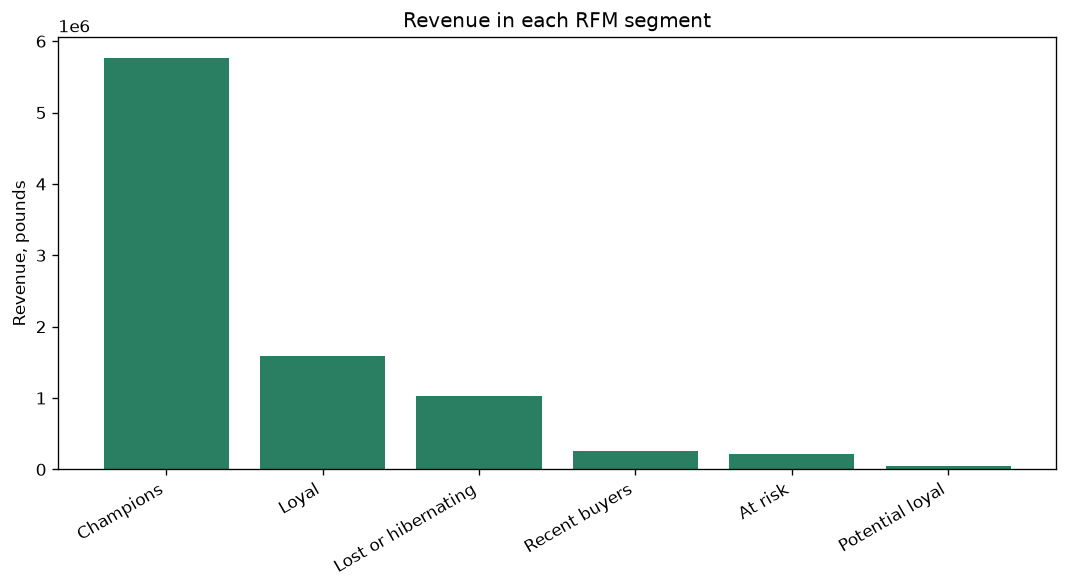

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(seg['segment'], seg['revenue'], color='#2a7f62')
ax.set_title('Revenue in each RFM segment')
ax.set_ylabel('Revenue, pounds')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(CHARTS / '11_segment_revenue.png')
plt.show()

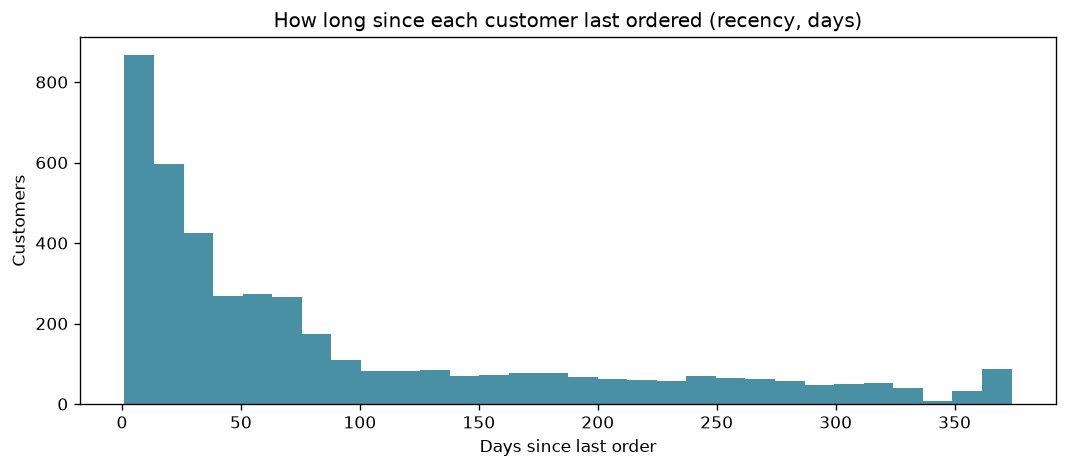

Customers with recency over 90 days, percent: 33.4
Customers with recency over 180 days, percent: 19.8


In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(rfm['recency'], bins=30, color='#4a90a4')
ax.set_title('How long since each customer last ordered (recency, days)')
ax.set_xlabel('Days since last order')
ax.set_ylabel('Customers')
plt.tight_layout()
plt.savefig(CHARTS / '12_recency_histogram.png')
plt.show()
print('Customers with recency over 90 days, percent:', round((rfm['recency'] > 90).mean() * 100, 1))
print('Customers with recency over 180 days, percent:', round((rfm['recency'] > 180).mean() * 100, 1))

## What we learned

Champions are 797 customers, or 18.4 percent of customers, but they account for 5,767,945.43 pounds, or 64.7 percent of clean revenue. Loyal customers add 831 customers and 1,595,780.54 pounds. Together, Champions and Loyal customers are 37.5 percent of customers and 82.6 percent of revenue. That is a strong concentration, and it is the main practical lesson of this notebook: keeping the best customers matters more, in money terms, than winning the same number of one time buyers. Lost or hibernating customers are the largest group, at 1,717 customers, but only 1,023,936.75 pounds. The median customer last ordered 51 days before the reference date, placed 2 orders, and spent 674.48 pounds. The mean is much higher than the median, because a few wholesale buyers spend very large sums, so the median is the safer typical value to quote.

Next: notebook 05 forecasts sales with a simple method, and adds two original signals.